# Bank Customer Churn Prediction

**Business question:** Which bank customers are about to leave, and what can the bank do to keep them?

A customer who closes their account takes their balance and future revenue with them. In this dataset, **1 in 5 customers left**. This notebook:

1. Explores **who** leaves (age, country, activity, products)
2. Trains 3 machine-learning models to predict churn and picks the best one
3. Turns the model into a **call list** a retention team can actually use
4. Ends with recommendations

**Data:** 10,000 customers of a European bank (France, Germany, Spain), 14 columns. `Exited = 1` means the customer left.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_curve)
from sklearn.inspection import permutation_importance

# One consistent look for every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
SEED = 42   # fixed seed so results are the same every run

## 2. Load and check the data

In [2]:
df = pd.read_csv("../data/Churn_Modelling.csv")
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Any missing values or duplicate customers?
print("Missing values:", df.isna().sum().sum())
print("Duplicate customers:", df["CustomerId"].duplicated().sum())
df.describe().round(1)

Missing values: 0
Duplicate customers: 0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,5000.5,15690940.6,650.5,38.9,5.0,76485.9,1.5,0.7,0.5,100090.2,0.2
std,2886.9,71936.2,96.7,10.5,2.9,62397.4,0.6,0.5,0.5,57510.5,0.4
min,1.0,15565701.0,350.0,18.0,0.0,0.0,1.0,0.0,0.0,11.6,0.0
25%,2500.8,15628528.2,584.0,32.0,3.0,0.0,1.0,0.0,0.0,51002.1,0.0
50%,5000.5,15690738.0,652.0,37.0,5.0,97198.5,1.0,1.0,1.0,100193.9,0.0
75%,7500.2,15753233.8,718.0,44.0,7.0,127644.2,2.0,1.0,1.0,149388.2,0.0
max,10000.0,15815690.0,850.0,92.0,10.0,250898.1,4.0,1.0,1.0,199992.5,1.0


The data is clean: no missing values and no duplicate customers. `RowNumber`, `CustomerId` and `Surname` are just IDs, so they can't help predict churn. We drop them.

In [4]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
churn_rate = df["Exited"].mean()
print(f"Overall churn rate: {churn_rate:.1%}  ({df['Exited'].sum():,} of {len(df):,} customers left)")

Overall churn rate: 20.4%  (2,037 of 10,000 customers left)


## 3. Who leaves? (exploratory analysis)

Each chart shows the churn rate for one group. The dashed line is the bank-wide average.

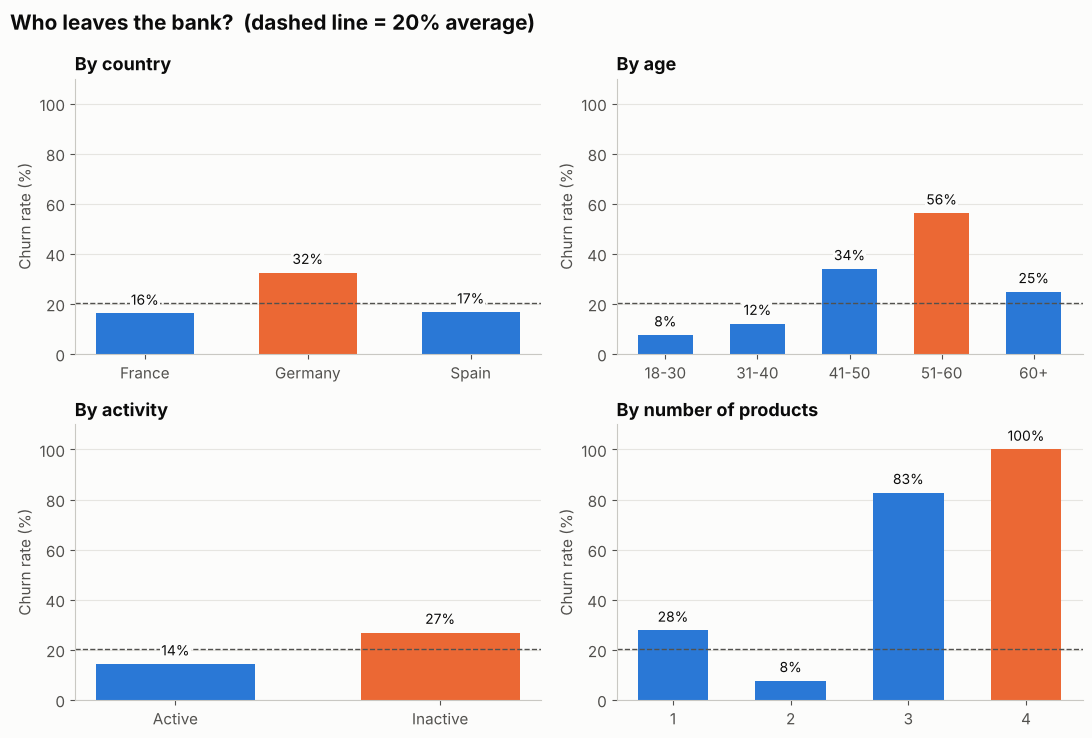

In [5]:
df["AgeBand"] = pd.cut(df["Age"], [17, 30, 40, 50, 60, 100],
                       labels=["18-30", "31-40", "41-50", "51-60", "60+"])
df["Active"] = df["IsActiveMember"].map({1: "Active", 0: "Inactive"})

def churn_by(col):
    return df.groupby(col, observed=True)["Exited"].mean()

panels = [("Geography", "By country"), ("AgeBand", "By age"),
          ("Active", "By activity"), ("NumOfProducts", "By number of products")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (col, title) in zip(axes.flat, panels):
    rates = churn_by(col)
    worst = rates.idxmax()
    colors = [ORANGE if k == worst else BLUE for k in rates.index]
    bars = ax.bar(rates.index.astype(str), rates.values * 100, color=colors, width=0.6)
    ax.axhline(churn_rate * 100, color=MUTED, linestyle="--", linewidth=1)
    for b, v in zip(bars, rates.values):
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 3.5, f"{v:.0%}", ha="center",
                color=INK, fontsize=10,
                bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=0.8))
    ax.set_title(title)
    ax.set_ylim(0, 110)
    ax.set_ylabel("Churn rate (%)")
    ax.grid(axis="x", visible=False)
fig.suptitle("Who leaves the bank?  (dashed line = 20% average)", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig("../images/churn_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# The numbers behind the charts
for col, _ in panels:
    print(churn_by(col).map("{:.1%}".format).to_string(), "\n")
print("Women:", f"{churn_by('Gender')['Female']:.1%}", "| Men:", f"{churn_by('Gender')['Male']:.1%}")

Geography
France     16.2%
Germany    32.4%
Spain      16.7% 

AgeBand
18-30     7.5%
31-40    12.1%
41-50    34.0%
51-60    56.2%
60+      24.8% 

Active
Active      14.3%
Inactive    26.9% 

NumOfProducts
1     27.7%
2      7.6%
3     82.7%
4    100.0% 

Women: 25.1% | Men: 16.5%


In [7]:
# How much money walks out the door?
lost = df.loc[df["Exited"] == 1, "Balance"].sum()
total = df["Balance"].sum()
print(f"Churned customers held {lost/1e6:.1f}M of {total/1e6:.1f}M in balances ({lost/total:.0%})")

Churned customers held 185.6M of 764.9M in balances (24%)


**What the data says:**

- **Germany churns at about 32%**, double France and Spain (about 16-17%).
- **Age matters most.** Customers aged 51-60 leave at about 56%, compared with under 8% for 18-30 year olds.
- **Inactive members leave about twice as often** as active ones (27% vs 14%).
- **2 products is the sweet spot** (8% churn). One product means 28% churn, and customers with 3 or 4 products leave at 83-100%, which points to a problem with those bundles.
- Churned customers took about **a quarter of all deposits** with them.

## 4. Prepare the data for machine learning

- **Features (X):** the 10 customer columns. **Target (y):** `Exited`.
- **Train/test split:** 80% of customers to train, 20% held back to test. `stratify` keeps the 20% churn rate the same in both parts.
- **Pipeline:** numbers are scaled, and text columns (country, gender) become 0/1 columns (*one-hot encoding*). A pipeline applies the same steps to train and test data, so no information leaks from the test set.

In [8]:
features = ["CreditScore", "Geography", "Gender", "Age", "Tenure", "Balance",
            "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
X, y = df[features], df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

numeric = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
           "HasCrCard", "IsActiveMember", "EstimatedSalary"]
categorical = ["Geography", "Gender"]
prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="first"), categorical),
])
print(f"Train: {len(X_train):,} customers | Test: {len(X_test):,} customers")

Train: 8,000 customers | Test: 2,000 customers


## 5. Train and compare 3 models

- **Logistic Regression:** a simple, explainable baseline
- **Random Forest:** many decision trees that vote
- **Gradient Boosting:** trees built one after another, each fixing the last one's mistakes

Only 20% of customers churn, so `class_weight="balanced"` tells each model to pay extra attention to churners. Otherwise a model could score 80% accuracy by predicting "nobody leaves".

**How we score them:**
- **ROC-AUC:** how well the model ranks risky customers above safe ones (0.5 = guessing, 1.0 = perfect)
- **Recall:** of the customers who really left, how many did we catch?
- **Precision:** of the customers we flagged, how many really left?

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                        class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

results, fitted, scores = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]      # churn probability for each test customer
    pred = (prob >= 0.5).astype(int)
    fitted[name], scores[name] = pipe, prob
    results.append({"Model": name,
                    "CV ROC-AUC": cv_auc,
                    "Test ROC-AUC": roc_auc_score(y_test, prob),
                    "Recall": recall_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "F1": f1_score(y_test, pred)})

results = pd.DataFrame(results).set_index("Model").round(3)
results

,CV ROC-AUC,Test ROC-AUC,Recall,Precision,F1
Model,,,,,
Logistic Regression,0.766,0.777,0.700,0.388,0.499
Random Forest,0.859,0.862,0.708,0.555,0.622
Gradient Boosting,0.854,0.852,0.668,0.540,0.597


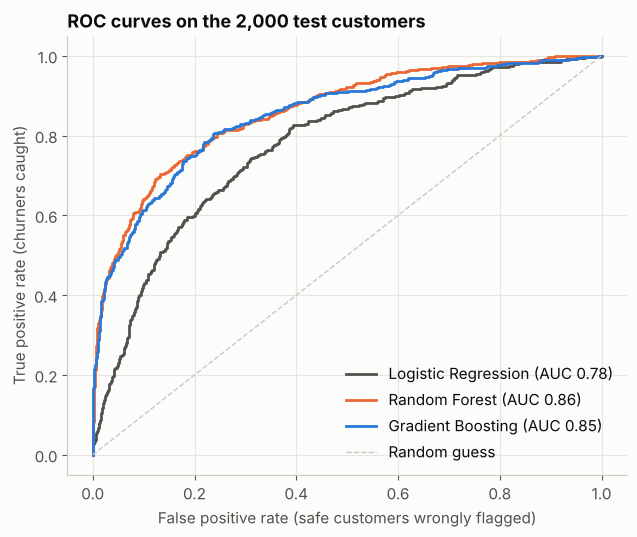

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (name, prob), color in zip(scores.items(), [MUTED, ORANGE, BLUE]):
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
ax.plot([0, 1], [0, 1], color="#c9c8c3", linestyle="--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate (safe customers wrongly flagged)")
ax.set_ylabel("True positive rate (churners caught)")
ax.set_title("ROC curves on the 2,000 test customers")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig("../images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**At default settings Random Forest leads:** ROC-AUC about 0.86, and its cross-validation score is almost the same, so it isn't overfitting. It catches about 7 in 10 churners, and more than half of the customers it flags really do leave. Logistic Regression scores lower because churn doesn't rise in a straight line. Age, for example, rises then falls. Next, we tune the two tree models to see which is best.

## 6. Tune the model (hyperparameter search)

The models above used sensible default settings. **RandomizedSearchCV** tries 20 random combinations of settings for Random Forest and Gradient Boosting, scores each with 5-fold cross-validation **on the training data only**, and keeps the best. The test set stays untouched until the final check.

In [11]:
from sklearn.model_selection import RandomizedSearchCV

search_spaces = {
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1), {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [6, 8, 10, 12, None],
        "model__min_samples_leaf": [1, 3, 5, 10, 20],
        "model__max_features": ["sqrt", 0.5, 0.7]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), {
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_iter": [200, 300, 500],
        "model__max_depth": [3, 4, 6, None],
        "model__min_samples_leaf": [10, 20, 40, 80],
        "model__l2_regularization": [0.0, 0.1, 1.0]}),
}
tuned, tuned_rows = {}, []
for name, (model, grid) in search_spaces.items():
    search = RandomizedSearchCV(Pipeline([("prep", prep), ("model", model)]), grid, n_iter=20,
                                scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    test_auc = roc_auc_score(y_test, search.best_estimator_.predict_proba(X_test)[:, 1])
    tuned_rows.append({"Model": name + " (tuned)", "CV ROC-AUC": search.best_score_,
                       "Test ROC-AUC": test_auc})
    print(name, "best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

tuned_table = pd.DataFrame(tuned_rows).set_index("Model").round(3)
tuned_table

Random Forest best settings: {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 8}


Gradient Boosting best settings: {'min_samples_leaf': 20, 'max_iter': 500, 'max_depth': 3, 'learning_rate': 0.02, 'l2_regularization': 0.0}


,CV ROC-AUC,Test ROC-AUC
Model,,
Random Forest (tuned),0.862,0.866
Gradient Boosting (tuned),0.865,0.869


In [12]:
final_name = tuned_table["CV ROC-AUC"].idxmax().replace(" (tuned)", "")   # choose by CV, not by test score
final_model = tuned[final_name]
final_prob = final_model.predict_proba(X_test)[:, 1]
print(f"Final model: {final_name} (tuned) | test ROC-AUC = {roc_auc_score(y_test, final_prob):.3f}")

Final model: Gradient Boosting (tuned) | test ROC-AUC = 0.869


We pick the final model by its **cross-validation** score, not its test score. Choosing by test score would quietly overfit to the test set.

## 7. From model to action: who should the retention team call?

A bank can't call every customer. So we rank customers by churn risk and ask: **if the team calls the riskiest X%, what share of all churners do they reach?** This is called a *gains chart*.

Calling the riskiest 20% of customers reaches 62% of all churners (vs 20% with a random list) - 3.1x more efficient.


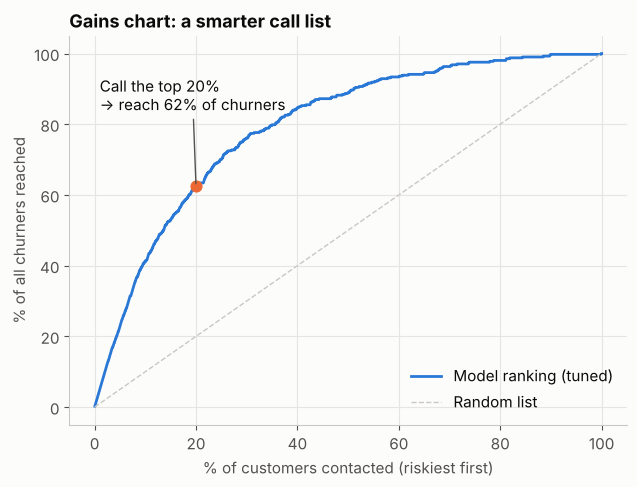

In [13]:
prob = final_prob
order = np.argsort(-prob)                          # riskiest first
caught = np.cumsum(y_test.values[order]) / y_test.sum()
contacted = np.arange(1, len(order) + 1) / len(order)

top20 = caught[int(0.2 * len(order)) - 1]
print(f"Calling the riskiest 20% of customers reaches {top20:.0%} of all churners "
      f"(vs 20% with a random list) - {top20/0.2:.1f}x more efficient.")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(contacted * 100, caught * 100, color=BLUE, linewidth=2, label="Model ranking (tuned)")
ax.plot([0, 100], [0, 100], color="#c9c8c3", linestyle="--", linewidth=1, label="Random list")
ax.scatter([20], [top20 * 100], color=ORANGE, s=60, zorder=3)
ax.annotate(f"Call the top 20%\n-> reach {top20:.0%} of churners", (20, top20 * 100),
            xytext=(1, 84), ha="left", color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xlabel("% of customers contacted (riskiest first)")
ax.set_ylabel("% of all churners reached")
ax.set_title("Gains chart: a smarter call list")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig("../images/gains_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
cm = confusion_matrix(y_test, (prob >= 0.5).astype(int))
pd.DataFrame(cm, index=["Actually stayed", "Actually left"],
             columns=["Predicted stay", "Predicted leave"])

,Predicted stay,Predicted leave
Actually stayed,1282,311
Actually left,92,315


## 8. What drives churn?

**Permutation importance** shuffles one column at a time and measures how much the model's ROC-AUC drops. The bigger the drop, the more the model relies on that column. It is measured on the test customers, so it reflects real predictive power.

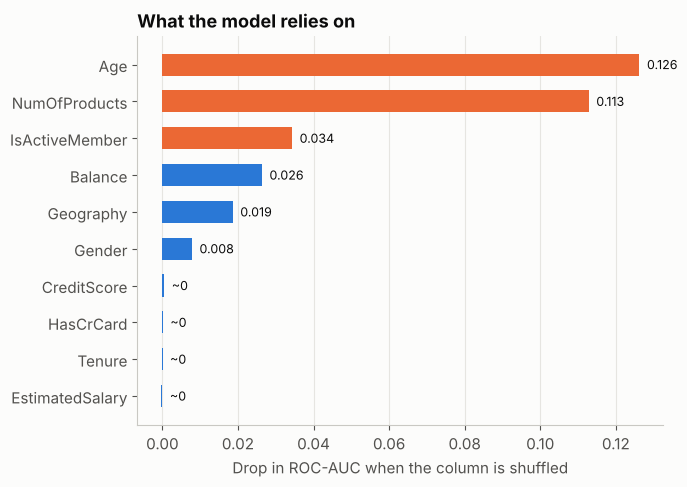

Age                0.126
NumOfProducts      0.113
IsActiveMember     0.034
Balance            0.026
Geography          0.019
Gender             0.008
CreditScore        0.000
HasCrCard          0.000
Tenure             0.000
EstimatedSalary   -0.000
dtype: float64

In [15]:
imp = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
colors = [ORANGE if v >= importance.nlargest(3).min() else BLUE for v in importance.values]
ax.barh(importance.index, importance.values, color=colors, height=0.6)
for i, v in enumerate(importance.values):
    label = f"{v:.3f}" if abs(v) >= 0.005 else "~0"
    ax.text(max(v, 0) + 0.002, i, label, va="center", color=INK, fontsize=9)
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
ax.set_title("What the model relies on")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(3)

**Age and number of products** drive most of the predictions, followed by active membership, balance and country. Gender adds a little. Credit score, salary, tenure and owning a credit card add almost nothing.

## 9. Choose the threshold that makes the most money

By default a model flags a customer when the churn probability is 50% or more. But the right cut-off depends on **money**: every call costs something, and every customer saved is worth something. The assumptions are below. Change them and re-run to match a real bank's numbers.

Best threshold: 0.51 -> call 608 customers, catch 313 churners, profit 63,500
Default 0.50:  call 626, profit 63,200
Call everyone: profit 22,100


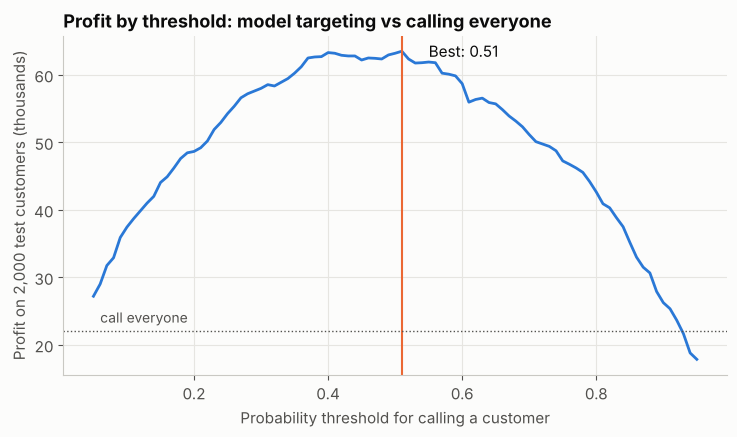

In [16]:
OFFER_COST   = 50     # cost of calling a customer + the retention offer
CUSTOMER_VAL = 1000   # value of keeping one customer who would have left (yearly profit)
SAVE_RATE    = 0.30   # share of contacted churners who stay because of the offer

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
rows = []
for t in thresholds:
    flagged = final_prob >= t
    caught = (flagged & (y_test.values == 1)).sum()
    profit = caught * SAVE_RATE * CUSTOMER_VAL - flagged.sum() * OFFER_COST
    rows.append({"threshold": t, "customers_called": flagged.sum(), "churners_caught": caught, "profit": profit})
profit_df = pd.DataFrame(rows).set_index("threshold")

best_t = profit_df["profit"].idxmax()
at_half = profit_df.loc[0.5]
call_all = y_test.sum() * SAVE_RATE * CUSTOMER_VAL - len(y_test) * OFFER_COST
print(f"Best threshold: {best_t:.2f} -> call {profit_df.loc[best_t, 'customers_called']:,} customers, "
      f"catch {profit_df.loc[best_t, 'churners_caught']:,} churners, profit {profit_df.loc[best_t, 'profit']:,.0f}")
print(f"Default 0.50:  call {at_half['customers_called']:,.0f}, profit {at_half['profit']:,.0f}")
print(f"Call everyone: profit {call_all:,.0f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(profit_df.index, profit_df["profit"] / 1000, color=BLUE, linewidth=2)
ax.axvline(best_t, color=ORANGE, linewidth=1.5)
ax.axhline(call_all / 1000, color=MUTED, linestyle=":", linewidth=1)
ax.text(0.06, call_all / 1000 + 1.2, "call everyone", color=MUTED, fontsize=10)
ax.annotate(f"Best: {best_t:.2f}", (best_t, profit_df['profit'].max() / 1000),
            xytext=(best_t + 0.04, profit_df['profit'].max() / 1000), color=INK, va="center")
ax.set_xlabel("Probability threshold for calling a customer")
ax.set_ylabel("Profit on 2,000 test customers (thousands)")
ax.set_title("Profit by threshold: model targeting vs calling everyone")
fig.tight_layout(); fig.savefig("../images/profit_threshold.png", dpi=150, bbox_inches="tight"); plt.show()

**Targeting with the model makes about 3 times more profit than calling everyone.** With these assumptions the best cut-off happens to sit near 0.5, because `class_weight="balanced"` already shifts the model's probabilities towards catching churners. The next cell shows how the best threshold moves when the costs change.

In [17]:
def best_threshold(cost, value, save_rate):
    profits = [((final_prob >= t) & (y_test.values == 1)).sum() * save_rate * value
               - (final_prob >= t).sum() * cost for t in thresholds]
    i = int(np.argmax(profits))
    return thresholds[i], (final_prob >= thresholds[i]).sum(), profits[i]

scenarios = {"Base case (50 / 1,000 / 30%)": (50, 1000, 0.30),
             "Expensive offer (150 / 1,000 / 30%)": (150, 1000, 0.30),
             "Cheap SMS nudge (5 / 1,000 / 10%)": (5, 1000, 0.10),
             "High-value customers (50 / 3,000 / 30%)": (50, 3000, 0.30)}
sens = pd.DataFrame([dict(zip(["best threshold", "customers called", "profit"], best_threshold(*v)))
                     for v in scenarios.values()], index=scenarios.keys())
sens.index.name = "Scenario (offer cost / customer value / save rate)"
sens

,best threshold,customers called,profit
Scenario (offer cost / customer value / save rate),,,
"Base case (50 / 1,000 / 30%)",0.51,608,63500.0
"Expensive offer (150 / 1,000 / 30%)",0.77,252,21000.0
"Cheap SMS nudge (5 / 1,000 / 10%)",0.18,1412,32340.0
"High-value customers (50 / 3,000 / 30%)",0.18,1412,284000.0


## 10. Save the model for the app

The final pipeline (pre-processing + model) and the chosen threshold are saved, so the Streamlit app in `app/` can score new customers without retraining.

In [18]:
import joblib, json, os
os.makedirs("../models", exist_ok=True)
joblib.dump(final_model, "../models/churn_model.joblib", compress=3)
json.dump({"model": final_name + " (tuned)", "threshold": float(best_t),
           "test_roc_auc": round(float(roc_auc_score(y_test, final_prob)), 3),
           "overall_churn_rate": round(float(churn_rate), 4)},
          open("../models/model_info.json", "w"), indent=2)
print("Saved model:", round(os.path.getsize("../models/churn_model.joblib") / 1e6, 1), "MB")

Saved model: 0.1 MB


## 11. Recommendations

1. **Score every customer monthly** with the saved model, and call everyone above the profit-maximising threshold (section 9). Even a list of just the riskiest 20% reaches about 6 in 10 future churners, about 3 times better than random.
2. **Fix the 3-4 product bundles.** Almost everyone with 3 or 4 products leaves. Review how these bundles are sold and priced.
3. **Move single-product customers to 2 products.** Churn falls from 28% to 8%. A targeted second-product offer (a savings account or a card) is the cheapest win.
4. **Re-engage inactive members** with app nudges and personal outreach. They churn twice as much.
5. **Give customers aged 45-60 a relationship manager.** About half of them leave, and they hold slightly above-average balances.
6. **Investigate Germany.** Churn is double the other countries, which suggests competition or service problems specific to that market.

**Next steps for the model:** replace the cost assumptions with the bank's real numbers, add behaviour over time (logins, transactions), and retrain every quarter.